In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import random

import tensorflow as tf
from tensorflow.keras import layers, models

In [2]:
## Creates list of all axles for use in reading in the files
axle_list = np.array(["Car1_Axle1.fit", "Car1_Axle2.fit", "Car1_Axle3.fit", "Car1_Axle4.fit", "Car2_Axle1.fit", "Car2_Axle2.fit", "Car2_Axle3.fit", "Car2_Axle4.fit", "Car3_Axle1.fit", "Car3_Axle2.fit", "Car3_Axle3.fit", "Car3_Axle4.fit", "Car4_Axle1.fit", "Car4_Axle2.fit", "Car4_Axle3.fit", "Car4_Axle4.fit", "Car5_Axle1.fit", "Car5_Axle2.fit", "Car5_Axle3.fit", "Car5_Axle4.fit", "Car6_Axle1.fit", "Car6_Axle2.fit", "Car6_Axle3.fit", "Car6_Axle4.fit", "Car7_Axle1.fit", "Car7_Axle2.fit", "Car7_Axle3.fit", "Car7_Axle4.fit", "Car8_Axle1.fit", "Car8_Axle2.fit", "Car8_Axle3.fit", "Car8_Axle4.fit", "Car9_Axle1.fit", "Car9_Axle2.fit", "Car9_Axle3.fit", "Car9_Axle4.fit", "Car10_Axle1.fit", "Car10_Axle2.fit", "Car10_Axle3.fit", "Car10_Axle4.fit", "Car11_Axle1.fit", "Car11_Axle2.fit", "Car11_Axle3.fit", "Car11_Axle4.fit", "Car12_Axle1.fit", "Car12_Axle2.fit", "Car12_Axle3.fit", "Car12_Axle4.fit", "Car13_Axle1.fit", "Car13_Axle2.fit", "Car13_Axle3.fit", "Car13_Axle4.fit", "Car14_Axle1.fit", "Car14_Axle2.fit", "Car14_Axle3.fit", "Car14_Axle4.fit"])
axle_count = len(axle_list)


In [3]:
## Reads in all Fit files, splitting them between right and left wheel and splitting each wheel into its composite x and y coordinates
rxs = []
rys = []
lxs = []
lys = []

for axle in axle_list:
    df = pd.read_csv(axle, skiprows = 3)
    cap = len(df)
    xstep = []
    ystep = []
    side = "right"
    
    for i in range(cap - 2):
        step = df.iloc[i].str.split().tolist()[0]
        
        if len(step) == 1:
            side = "left" 
            rxs.append(xstep)
            rys.append(ystep)
            xstep = []
            ystep = []
        elif (side == "left"):
            xstep.append(float(step[0]))
            ystep.append(float(step[1]))
        elif (side == "right"):
            xstep.append(float(step[0]))
            ystep.append(float(step[1]))

    lxs.append(xstep)
    lys.append(ystep)



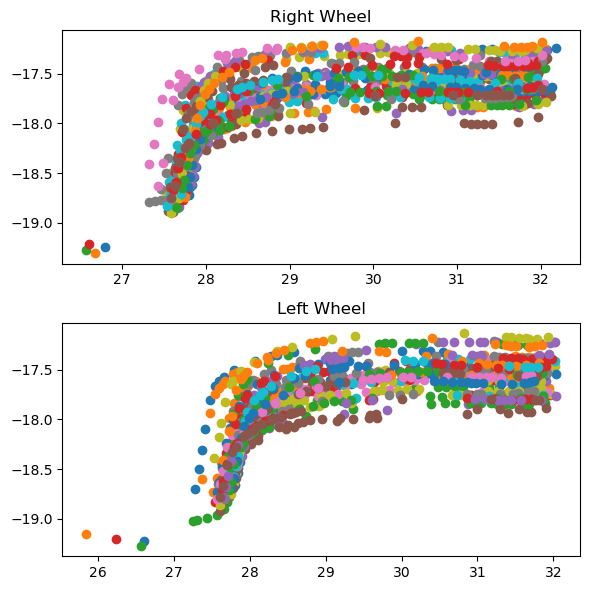

In [4]:
## Graphing the current Points for a Sanity Check
fig, ax = plt.subplots(2, 1, figsize=(6, 6))

for i in range(axle_count):
    ax[0].scatter(rxs[i], rys[i])
    ax[0].set_title("Right Wheel")
    
    ax[1].scatter(lxs[i], lys[i])
    ax[1].set_title("Left Wheel")

plt.tight_layout()
plt.show()

In [5]:
## Reads in eq_con results file and uses it to assign each wheel whether it is Hunting (True) or Not (False)
fit_res = pd.read_excel("Eq_Con_Fit_Results.xlsm")

hunt_df = fit_res[["Filename", "Empty Axle from Lat Disp HS [mph]", "Loaded Axle from Lat Disp HS [mph]"]]
hunt_df = hunt_df[~hunt_df['Filename'].isin(["KRWHL_RProfile 1.wnt", "KRWHL_RProfile 2.wnt", "KRWHL_RProfile 3.wnt", "KRWHL_RProfile 4.wnt", "KRWHL_RProfile 5.wnt", "KRWHL_RProfile 6.wnt","KRWHL_RProfile 7.wnt"])]
hunt_df.reset_index(drop=True, inplace=True)

hunting_empty = []
hunting_full = []
ehunt = False
fhunt = False
step = 0

for i in range(len(hunt_df["Filename"])):
    if hunt_df["Empty Axle from Lat Disp HS [mph]"][i] != 80:
        ehunt = True

    if hunt_df["Loaded Axle from Lat Disp HS [mph]"][i] != 80:
        fhunt = True

    if step == 6:
        step = -1
        if ehunt == True:
            hunting_empty.append(True)
            ehunt = False
        else: 
            hunting_empty.append(False)

        if fhunt == True:
            hunting_full.append(True)
            fhunt = False
        else: 
            hunting_full.append(False)
    
    step += 1

y_empty_temp = [hunting_empty, hunting_empty]
y_empty = [item for sublist in y_empty_temp for item in sublist]
y_empty = np.array(y_empty)

In [6]:
## All data needs to be the same length for modeling ot work. Length of 28 chosen as it sits comfotablly in the middle with out loosing too much data 

## 3 wheels need to shortened
ils = [27, 28, 49]
rxs[ils[0]], rys[ils[0]] = rxs[ils[0]][2:30], rys[ils[0]][2:30]

endstep = len(rxs[ils[1]])
stepxs = rxs[ils[1]][0:endstep - 11] + rxs[ils[1]][endstep - 10:endstep - 8] + rxs[ils[1]][endstep-7:endstep-6] + rxs[ils[1]][endstep-5:endstep]
stepys = rys[ils[1]][0:endstep - 11] + rys[ils[1]][endstep - 10:endstep - 8] + rys[ils[1]][endstep-7:endstep-6] + rys[ils[1]][endstep-5:endstep]
rxs[ils[1]], rys[ils[1]] = stepxs, stepys

endstep2 = len(rxs[ils[2]])
stepxs2 = rxs[ils[2]][0:endstep2 - 7] + rxs[ils[2]][endstep2 - 6:endstep2]
stepys2 = rys[ils[2]][0:endstep2 - 7] + rys[ils[2]][endstep2 - 6:endstep2]
rxs[ils[2]], rys[ils[2]] = stepxs2, stepys2

## rest some werid outliers need to be removed
rxs[40], rys[40] = rxs[40][1:len(rxs[40])-1], rys[40][1:len(rys[40])-1]
rxs[41], rys[41] = rxs[41][1:len(rxs[41])-1], rys[41][1:len(rys[41])-1]
rxs[42], rys[42] = rxs[42][1:len(rxs[42])-1], rys[42][1:len(rys[42])-1]
rxs[43], rys[43] = rxs[43][1:len(rxs[43])-1], rys[43][1:len(rys[43])-1]

lxs[40], lys[40] = lxs[40][1:len(lxs[40])-1], lys[40][1:len(lys[40])-1]
lxs[41], lys[41] = lxs[41][1:len(lxs[41])-1], lys[41][1:len(lys[41])-1]
lxs[42], lys[42] = lxs[42][1:len(lxs[42])-1], lys[42][1:len(lys[42])-1]
lxs[43], lys[43] = lxs[43][1:len(lxs[43])-1], lys[43][1:len(lys[43])-1]

## All left need to be lengthened to 38 pairs long

for i in range(len(rxs)):
    rs = rxs[i]
    rsy = rys[i]
    ls = lxs[i]
    lsy = lys[i]
    
    while len(rs) != 28:
        whle = len(rs)
        frs, brs = rs[0:15], rs[15:whle]
        frsy, brsy = rsy[0:15], rsy[15:whle]
        rs = frs + [(frs[len(frs)-1] + brs[0])/2] + brs
        rsy = frsy + [(frsy[len(frsy)-1] + brsy[0])/2] + brsy
    rxs[i] = rs
    rys[i] = rsy
    
    while len(ls) != 28:
        whle = len(ls)
        fls, bls = ls[0:15], ls[15:whle]
        flsy, blsy = lsy[0:15], lsy[15:whle]
        ls = fls + [(fls[len(fls)-1] + bls[0])/2] + bls
        lsy = flsy + [(flsy[len(flsy)-1] + blsy[0])/2] + blsy
    lxs[i] = ls
    lys[i] = lsy



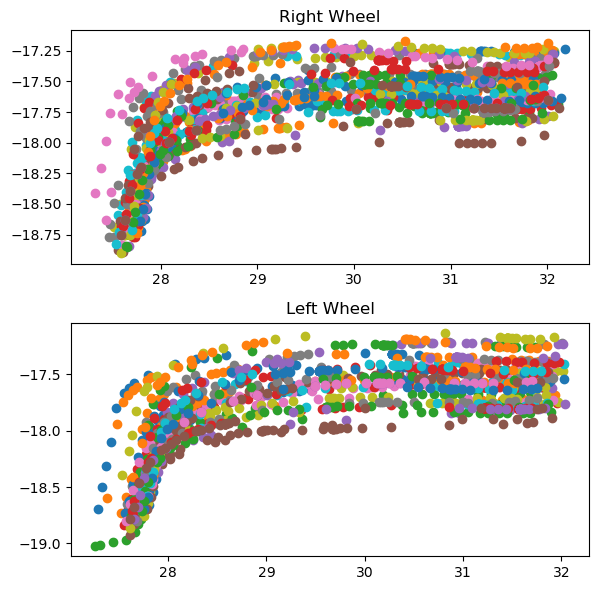

In [7]:
## Graphing for Sanity Check. If above Worked there should be no strange outlier points
fig, ax = plt.subplots(2, 1, figsize=(6, 6))

for i in range(axle_count):
    ax[0].scatter(rxs[i], rys[i])
    ax[0].set_title("Right Wheel")
    
    ax[1].scatter(lxs[i], lys[i])
    ax[1].set_title("Left Wheel")

plt.tight_layout()
plt.show()

In [8]:
## Turns all wheel Data in to a singular data frame named "X"
xr = []
xl = []
wheel = []

for i in range(axle_count):
    for j in range(len(rxs[i])):
        wheel.append([rxs[i][j], rys[i][j]])
    xr.append(wheel)
    wheel = []

for i in range(axle_count):
    for j in range(len(lxs[i])):
        wheel.append([lxs[i][j], lys[i][j]])
    xl.append(wheel)
    wheel = []

x = np.array(xr + xl)
np.array(x).shape

## 112 unique wheels, 28 points ber wheel, each point has an x and a  ##

(112, 28, 2)

In [9]:
## split data into Test and Train data
xe_train, xe_test, ye_train, ye_test = train_test_split(x, y_empty, test_size = 30, random_state = 67)

In [11]:
## creates and runs Model on Training Data
model = models.Sequential([
        layers.Input(shape=(28,2)),
        layers.LSTM(90, return_sequences=False),
        layers.Dropout(0.3),
        layers.Dense(28, activation="relu"),
        layers.Dense(1, activation="sigmoid"),])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],)

model.fit(xe_train, ye_train, epochs = 100, batch_size = len(xe_train), validation_split = 0.2,)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.5538 - auc: 0.4512 - loss: 0.6827 - val_accuracy: 0.7647 - val_auc: 0.4712 - val_loss: 0.6312
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.7385 - auc: 0.5640 - loss: 0.5989 - val_accuracy: 0.7647 - val_auc: 0.4231 - val_loss: 0.5961
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.8308 - auc: 0.3712 - loss: 0.5650 - val_accuracy: 0.7647 - val_auc: 0.4423 - val_loss: 0.5727
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.8308 - auc: 0.4646 - loss: 0.5361 - val_accuracy: 0.7647 - val_auc: 0.4712 - val_loss: 0.5600
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.8308 - auc: 0.4276 - loss: 0.5113 - val_accuracy: 0.7647 - val_auc: 0.5096 - val_loss: 0.5512
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.8308 - auc: 0.3628 - loss: 0.5184 - val_accuracy: 0.7647 - val_auc: 0.5000 - val_loss: 0.5467
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/ste

In [12]:
## Predict Hunting based on Testing Data
pred = (model.predict(xe_test) > 0.5).T[0]

## Finds accuracy rate - % Correctly Predicted
print("Accuracy found to be at around" , 100*int(sum(ye_test == pred))/len(pred), "Percent")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step
Accuracy found to be at around 70.0 Percent


#### Model finds easiest method to be predicting true for every point so only able to hit ~70% Accuracy

#### If we balance out the data and make 50% where Hunting = True and 50% where hunting = False this Model will hopefully be more Accurate

In [13]:
## Creating Function to add new wheel data based off existing wheel data but slightly skewing its placement
## Original idea was to see if wheel measurements could be used to predict Hunting. 
## Using existing Wheel measurements and Offsetting them by a random amount should hopefully not skew the data too much		


def new_wheel_func(x, old_wheel_num):
    new_wheel = []
    new_x = random.uniform(0.001, 0.1)
    new_y = random.uniform(0.001, 0.1)
    for i in range(28):
        xa, ya = x[old_wheel_num][i]
        new_wheel.append([new_x + xa,new_y + ya])

    return new_wheel


In [14]:
## Run new_wheel_func to create new wheels
fal_ind = [i for i, val in enumerate(y_empty) if not val]
ls_chosen = fal_ind + fal_ind + fal_ind[0:18] + [3] + [6]
ls_tf = []

for index in ls_chosen:
    ls_tf.append(bool(y_empty[index]))    


for i in range(len(ls_tf)):
    new_wheel = new_wheel_func(x, ls_chosen[i])
    x = np.append(x, [new_wheel], axis = 0)
    y_empty = np.append(y_empty, ls_tf[i])


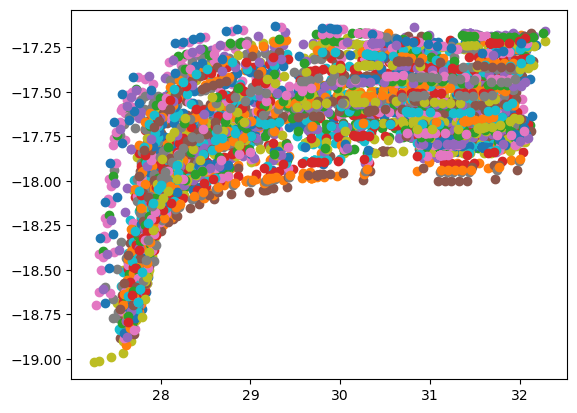

In [15]:
## Graphing for Sanity Check. Shoudl be LOTS of points
for i in range(len(x)):
    plt.scatter(x[i][:].T[0], x[i][:].T[1])

In [16]:
## Split new Data, Make new model and fit
xe_train, xe_test, ye_train, ye_test = train_test_split(x, y_empty, test_size = 30, random_state = 67)

model = models.Sequential([
        layers.Input(shape=(28,2)),
        layers.LSTM(90, return_sequences=False),
        layers.Dropout(0.3),
        layers.Dense(28, activation="relu"),
        layers.Dense(1, activation="sigmoid"),])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],)

model.fit(xe_train, ye_train, epochs = 100, batch_size = len(xe_train), validation_split = 0.2,)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5417 - auc: 0.3790 - loss: 0.7441 - val_accuracy: 0.4333 - val_auc: 0.5679 - val_loss: 0.7139
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.5583 - auc: 0.5147 - loss: 0.6912 - val_accuracy: 0.5667 - val_auc: 0.4910 - val_loss: 0.6926
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.4583 - auc: 0.4506 - loss: 0.7102 - val_accuracy: 0.5667 - val_auc: 0.5113 - val_loss: 0.6890
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.5500 - auc: 0.5407 - loss: 0.6932 - val_accuracy: 0.5667 - val_auc: 0.5498 - val_loss: 0.6891
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.4833 - auc: 0.4898 - loss: 0.6996 - val_accuracy: 0.5667 - val_auc: 0.4389 - val_loss: 0.6906
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.4583 - auc: 0.4667 - loss: 0.7064 - val_accuracy: 0.4333 - val_auc: 0.5882 - val_loss: 0.6940
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/ste

In [17]:
## Predict Again
pred = (model.predict(xe_test) > 0.5).T[0]
print("Accuracy found to be at around" , 100*int(sum(ye_test == pred))/len(pred), "Percent")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step
Accuracy found to be at around 50.0 Percent


#### Sadly the older model works more efficiently. Adding more wheels only confused the model moremore